# ISLP Chapter 12: Unsupervised Learning — Exercises 6 & 9

## Question 6 (Conceptual)

**Problem statement.** We saw in Section 12.2.2 that the principal component loading and score vectors provide an approximation to a matrix, in the sense of (12.5). Specifically, the principal component score and loading vectors solve the optimization problem given in (12.6):

$$
\underset{A \in \mathbb{R}^{n\times M},\; B \in \mathbb{R}^{p\times M}}{\text{minimize}} \left\{ \sum_{j=1}^{p}\sum_{i=1}^{n} \left( x_{ij} - \sum_{m=1}^{M} a_{im} b_{jm} \right)^{2} \right\} \tag{12.6}
$$

Now suppose that the $M$ principal component **score** vectors $z_{im},\; m = 1,\dots,M$, are already known (i.e., the matrix $A$, whose $(i,m)$ entry is $a_{im}=z_{im}$, is fixed). Using (12.6), explain why each of the first $M$ principal component **loading** vectors $\phi_{jm},\; m=1,\dots,M$, can be obtained by performing $p$ separate least‑squares linear regressions, where in each regression the score vectors are the predictors and one feature (column) of the data matrix is the response.

### Solution

With the scores $a_{im} = z_{im}$ held fixed, the only free parameters left in (12.6) are the entries of $B$, i.e. the loadings $b_{jm} = \phi_{jm}$. Substituting $a_{im}=z_{im}$ into the objective gives

$$
\underset{B \in \mathbb{R}^{p\times M}}{\text{minimize}} \left\{ \sum_{j=1}^{p} \underbrace{\sum_{i=1}^{n} \left( x_{ij} - \sum_{m=1}^{M} z_{im}\, \phi_{jm} \right)^{2}}_{f_j(\phi_{j1},\dots,\phi_{jM})} \right\}.
$$

The key observation is that the **outer sum over $j$ decouples**: for a fixed $j$, the inner term $f_j(\phi_{j1},\dots,\phi_{jM})$ depends *only* on the loadings $\phi_{j1},\dots,\phi_{jM}$ associated with feature $j$ — it does not involve the loadings for any other feature $j' \neq j$. Consequently, minimizing the whole sum $\sum_{j=1}^p f_j(\cdot)$ over all of $B$ jointly is equivalent to minimizing each $f_j(\cdot)$ **separately**, one $j$ at a time, and then stacking the $p$ solutions into the rows of $B$.

Now look closely at a single term:

$$
f_j(\phi_{j1},\dots,\phi_{jM}) = \sum_{i=1}^{n} \left( x_{ij} - \sum_{m=1}^{M} z_{im}\, \phi_{jm} \right)^{2}.
$$

This is exactly the residual sum of squares for an **ordinary least‑squares regression with no intercept**, in which:

- the **response** is the $j$-th column of the data matrix, $x_{1j}, x_{2j}, \dots, x_{nj}$ (feature $j$ across all $n$ observations), and
- the **predictors** are the $M$ principal‑component score vectors $z_{i1}, \dots, z_{iM}$ (the same $n \times M$ matrix of scores for every $j$), and
- the **coefficients to estimate** are $\phi_{j1},\dots,\phi_{jM}$, the loadings for feature $j$ on each of the $M$ components.

(There is no intercept term because the data are conventionally centered to have mean zero before performing PCA, so the best-fitting line/hyperplane passes through the origin.)

Therefore, minimizing (12.6) over $B$ for fixed $A=Z$ reduces to solving $p$ separate least-squares regressions — one for each feature $j = 1,\dots,p$ — where every regression uses the *same* $n\times M$ matrix of principal component scores as predictors, and only the response (the feature being predicted) changes from one regression to the next. The OLS solution to the $j$-th regression, $\hat\phi_j = (Z^\top Z)^{-1} Z^\top x_j$, gives exactly the $j$-th row of the optimal loading matrix $B$.

This is precisely the alternating-minimization intuition behind low-rank matrix approximation / PCA: for scores fixed, the optimal loadings solve $p$ regressions of the features on the scores; symmetrically (used in Exercise 11's matrix-completion algorithm), for loadings fixed, the optimal scores solve $n$ regressions of the observations on the loadings. Iterating between the two is exactly Algorithm 12.1.

## Question 9 (Applied)

**Problem statement.** Consider the `USArrests` data. We will now perform hierarchical clustering on the states.

(a) Using hierarchical clustering with complete linkage and Euclidean distance, cluster the states.

(b) Cut the dendrogram at a height that results in three distinct clusters. Which states belong to which clusters?

(c) Hierarchically cluster the states using complete linkage and Euclidean distance, after scaling the variables to have standard deviation one.

(d) What effect does scaling the variables have on the hierarchical clustering obtained? In your opinion, should the variables be scaled before the inter-observation dissimilarities are computed? Provide a justification for your answer.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.cluster.hierarchy import dendrogram, cut_tree
from scipy.cluster.hierarchy import linkage as hc_linkage
from sklearn.preprocessing import StandardScaler

%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 6)

### Load the data

In [2]:
USArrests = pd.read_csv('USArrests.csv', index_col=0)
USArrests.index.name = None
print(USArrests.shape)
USArrests.head()

(50, 4)


,Murder,Assault,UrbanPop,Rape
Alabama,13.2,236,58,21.2
Alaska,10.0,263,48,44.5
Arizona,8.1,294,80,31.0
Arkansas,8.8,190,50,19.5
California,9.0,276,91,40.6


### (a) Hierarchical clustering with complete linkage and Euclidean distance

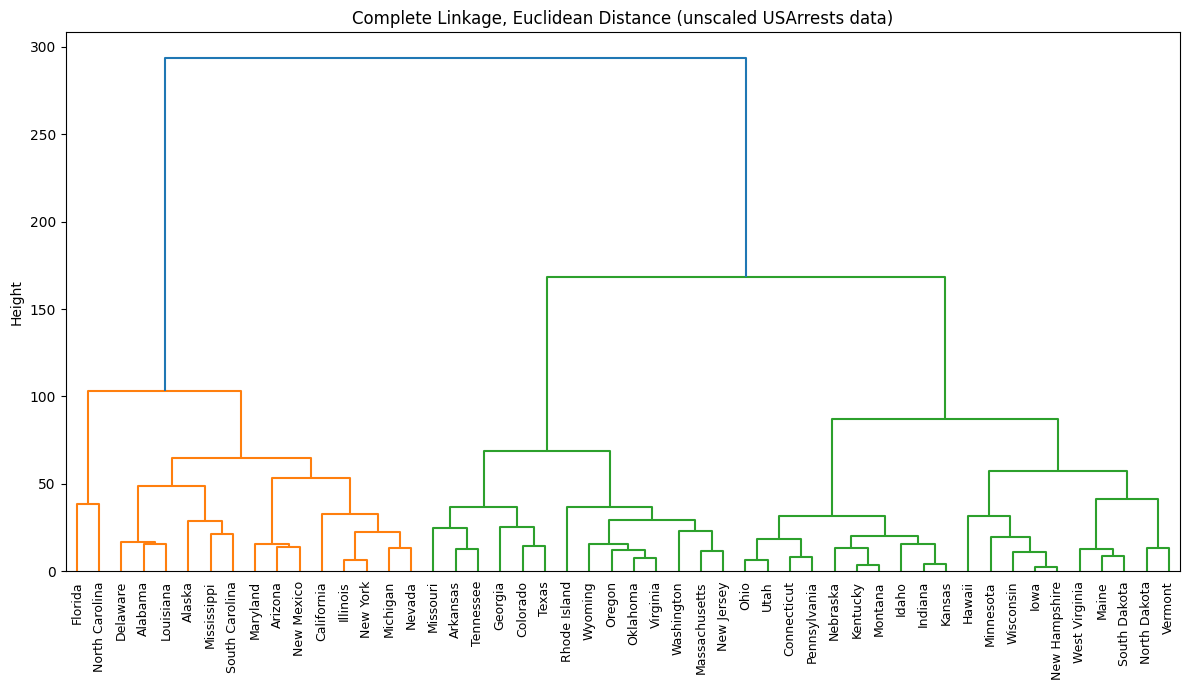

In [3]:
# scipy's linkage() with method='complete' and metric='euclidean' computes
# complete-linkage hierarchical clustering directly on the raw (unscaled) data
hc_complete = hc_linkage(USArrests, method='complete', metric='euclidean')

fig, ax = plt.subplots(figsize=(12, 7))
dendrogram(hc_complete,
           labels=USArrests.index.to_list(),
           leaf_rotation=90,
           leaf_font_size=9,
           ax=ax)
ax.set_title('Complete Linkage, Euclidean Distance (unscaled USArrests data)')
ax.set_ylabel('Height')
plt.tight_layout()
plt.show()

### (b) Cut the dendrogram to obtain three clusters

In [4]:
cluster_labels = cut_tree(hc_complete, n_clusters=3).reshape(-1)
clusters_unscaled = pd.Series(cluster_labels, index=USArrests.index, name='Cluster')

for c in sorted(clusters_unscaled.unique()):
    states = clusters_unscaled[clusters_unscaled == c].index.to_list()
    print(f"Cluster {c+1} ({len(states)} states):")
    print(", ".join(states))
    print()

Cluster 1 (16 states):
Alabama, Alaska, Arizona, California, Delaware, Florida, Illinois, Louisiana, Maryland, Michigan, Mississippi, Nevada, New Mexico, New York, North Carolina, South Carolina

Cluster 2 (14 states):
Arkansas, Colorado, Georgia, Massachusetts, Missouri, New Jersey, Oklahoma, Oregon, Rhode Island, Tennessee, Texas, Virginia, Washington, Wyoming

Cluster 3 (20 states):
Connecticut, Hawaii, Idaho, Indiana, Iowa, Kansas, Kentucky, Maine, Minnesota, Montana, Nebraska, New Hampshire, North Dakota, Ohio, Pennsylvania, South Dakota, Utah, Vermont, West Virginia, Wisconsin



In [5]:
# Cluster sizes
clusters_unscaled.value_counts().sort_index()

Cluster
0    16
1    14
2    20
Name: count, dtype: int64

### (c) Repeat, after scaling each variable to have standard deviation one

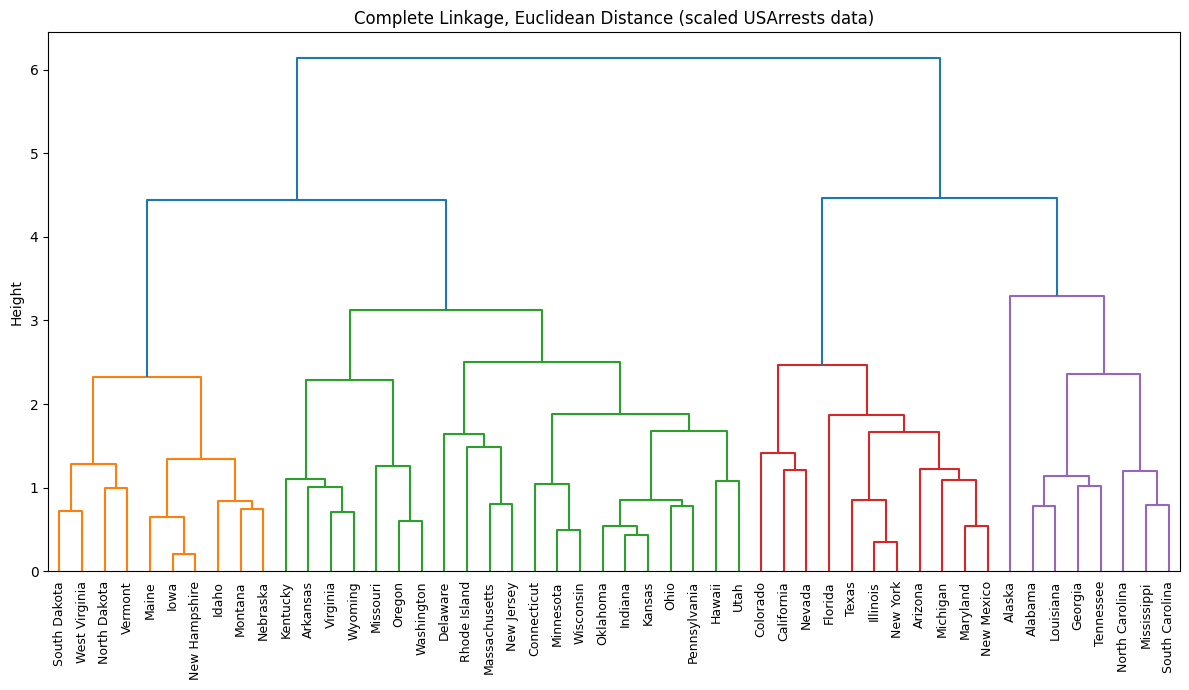

In [6]:
scaler = StandardScaler(with_mean=True, with_std=True)
USArrests_scaled = pd.DataFrame(
    scaler.fit_transform(USArrests),
    index=USArrests.index,
    columns=USArrests.columns
)

hc_complete_scaled = hc_linkage(USArrests_scaled, method='complete', metric='euclidean')

fig, ax = plt.subplots(figsize=(12, 7))
dendrogram(hc_complete_scaled,
           labels=USArrests_scaled.index.to_list(),
           leaf_rotation=90,
           leaf_font_size=9,
           ax=ax)
ax.set_title('Complete Linkage, Euclidean Distance (scaled USArrests data)')
ax.set_ylabel('Height')
plt.tight_layout()
plt.show()

In [7]:
cluster_labels_scaled = cut_tree(hc_complete_scaled, n_clusters=3).reshape(-1)
clusters_scaled = pd.Series(cluster_labels_scaled, index=USArrests_scaled.index, name='Cluster')

for c in sorted(clusters_scaled.unique()):
    states = clusters_scaled[clusters_scaled == c].index.to_list()
    print(f"Cluster {c+1} ({len(states)} states):")
    print(", ".join(states))
    print()

Cluster 1 (8 states):
Alabama, Alaska, Georgia, Louisiana, Mississippi, North Carolina, South Carolina, Tennessee

Cluster 2 (11 states):
Arizona, California, Colorado, Florida, Illinois, Maryland, Michigan, Nevada, New Mexico, New York, Texas

Cluster 3 (31 states):
Arkansas, Connecticut, Delaware, Hawaii, Idaho, Indiana, Iowa, Kansas, Kentucky, Maine, Massachusetts, Minnesota, Missouri, Montana, Nebraska, New Hampshire, New Jersey, North Dakota, Ohio, Oklahoma, Oregon, Pennsylvania, Rhode Island, South Dakota, Utah, Vermont, Virginia, Washington, West Virginia, Wisconsin, Wyoming



In [8]:
# Compare the unscaled- vs scaled-data cluster assignments directly
comparison = pd.crosstab(clusters_unscaled.rename('Unscaled'),
                          clusters_scaled.rename('Scaled'))
comparison

Scaled,0,1,2
Unscaled,,,
0,6,9,1
1,2,2,10
2,0,0,20


In [9]:
# Look at the scale (variance) of each variable to see why scaling matters here
USArrests.var().sort_values(ascending=False)

Assault     6945.165714
UrbanPop     209.518776
Rape          87.729159
Murder        18.970465
dtype: float64

### (d) Discussion — effect of scaling, and whether variables should be scaled

**What changes.** Comparing the two dendrograms and the crosstab above shows that scaling the variables **changes the resulting clusters**: several states switch cluster membership between the unscaled and scaled solutions (the crosstab is not diagonal). The overall shape of the dendrogram also changes — the relative heights at which fusions occur are different, because Euclidean distance on the raw data is dominated by whichever variable happens to have the largest numeric range.

**Why it happens.** Looking at the variances of the four features, `Assault` has a variance that is roughly 100–200 times larger than `Murder`, `UrbanPop`, or `Rape` (because assault counts are on a scale of hundreds, while the others are single- or double-digit percentages/rates). Euclidean distance is a sum of squared differences across variables, so **without scaling, the clustering is essentially driven by `Assault` alone** — the other three variables contribute comparatively little to the inter-state distances. After standardizing every variable to standard deviation one, all four variables contribute roughly equally to the dissimilarity measure, and the clustering instead reflects a more balanced combination of all the crime/urbanization measures.

**Should the variables be scaled?** In general, yes — the variables in this data set should be scaled before computing inter-observation dissimilarities, and this is the right default in most applications. The reasoning:

- The four variables are measured in genuinely different units (crimes per 100,000 residents for `Murder`, `Assault`, `Rape`, vs. a percentage for `UrbanPop`), so their numeric magnitudes are not directly comparable. There's no substantive reason `Assault` should be treated as 100+ times more important than `Murder` in defining similarity between states — that weighting is an artifact of the units chosen, not a meaningful signal.
- Standardizing to standard deviation one puts every variable on a common, unit-free scale, so each contributes comparably to the Euclidean distance, and the resulting clusters reflect a genuine balance of all the measured characteristics rather than being dominated by whichever variable has the largest raw variance.
- The general principle (echoed elsewhere in the chapter, e.g. for K-means and for PCA on variables measured in different units) is: *if the variables are measured on different scales, or in different units, they should be standardized before dissimilarities/distances are computed* — unless there is a specific, deliberate reason to weight one variable more heavily than another (e.g., domain knowledge that `Assault` genuinely should dominate the analysis), scaling should be applied.